### Build Basic ChatBot with LangGraph (Graph API)

In [10]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages


In [11]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

graph_builder=StateGraph(State)

In [4]:
graph_builder

In [12]:
import os
from dotenv import load_dotenv

load_dotenv()

True

In [13]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="meta-llama/llama-prompt-guard-2-86m")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.7', 'langchain': '1.4.10'}}, profile={'name': 'Llama Prompt Guard 2 86M', 'release_date': '2024-10-01', 'last_updated': '2024-10-01', 'open_weights': True, 'max_input_tokens': 512, 'max_output_tokens': 512, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': False, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x136a4ad50>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x136a4b750>, model_name='meta-llama/llama-prompt-guard-2-86m', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [22]:
llm=init_chat_model("groq:meta-llama/llama-prompt-guard-2-86m")

In [14]:
def chatbot(state:State):
    return {"messages": [llm.invoke(state["messages"])] }

In [9]:
graph_builder=StateGraph(State)

## Adding Node
graph_builder.add_node("llmChatBot", chatbot)

## Adding Edges
graph_builder.add_edge(START,"llmChatBot")
graph_builder.add_edge("llmChatBot", END)

# compile the chatbot
graph=graph_builder.compile()

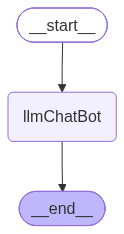

In [10]:
# Visualize the graph
from IPython.display import Image, display 

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [11]:
graph.invoke({"messages": "Hi"})

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='b94cf2ac-1410-4856-b6f2-b642bdbffcfe'),
  AIMessage(content='0.0007473019068129361', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 0, 'prompt_tokens': 3, 'total_tokens': 0, 'completion_time': 0.0, 'completion_tokens_details': None, 'prompt_time': 0.0, 'prompt_tokens_details': None, 'queue_time': 0.0, 'total_time': 0.0}, 'model_name': 'meta-llama/llama-prompt-guard-2-86m', 'system_fingerprint': 'fp_b69b76917b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1daf6-433d-7290-8b9d-2176d4432fc1-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 3, 'output_tokens': 0, 'total_tokens': 0})]}

In [2]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=2)
tool.invoke("What is langgraph")


{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] LangGraph illuminates the processes within an AI workflow, allowing full transparency of the agent’s state. Within LangGraph, the “state” feature serves as a memory bank that records and tracks all the valuable information processed by the AI system. It’s similar to a digital notebook where the system captures an

In [39]:
## custom func

def multiply(a: int, b: int)-> int:
    """Multiply a nad b

    Args:
        a (int): first int
        b (int): Second int
    
    Returns:
      int: __description_output int
    """
    return a * b


In [40]:
tools=[tool, multiply]
llm_with_tool = llm.bind_tools(tools)
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.7', 'langchain': '1.4.10'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x1423ba520>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x1423bafd0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted res

### CHAT MODEL

In [41]:
# CHAT Model

from langchain.chat_models import init_chat_model

# Use a tool-capable Groq model instead of prompt-guard
llm = init_chat_model("groq:openai/gpt-oss-120b")
llm_with_tool = llm.bind_tools(tools)


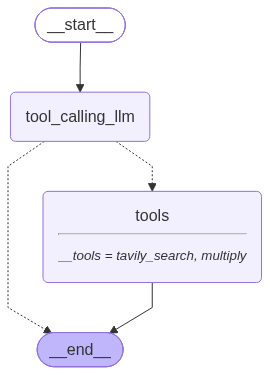

In [42]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image, display 

# Node Defination
def tool_calling_llm(state:State):
    return {"messages": llm_with_tool.invoke(state["messages"])}

# Graph
builder = StateGraph(State)
builder_graph = builder.add_node("tool_calling_llm",tool_calling_llm);
builder.add_node("tools", ToolNode(tools))


# Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)

builder.add_edge("tools", END)

graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))



In [32]:
result = graph.invoke({"messages":"What is the recent ai news"})

In [36]:
for m in result.messages:
    m.pretty_print()

AttributeError: 'dict' object has no attribute 'messages'

In [35]:
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_4dc4ecae-c320-4abe-ae80-adb5bcf5ae29)
 Call ID: fc_4dc4ecae-c320-4abe-ae80-adb5bcf5ae29
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.riskinfo.ai/post/ai-insights-key-global-developments-in-november-2026", "title": "AI Insights: Key Global Developments in November 2026", "content": "In the defence sector, Shield AI announced plans to acquire radar developer Echodyne in a $5.3 billion deal, alongside a $2.5 billion funding round that valued the company at $28.8 billion.\n\nIn the softwar

In [45]:
result = graph.invoke({"messages":"What is the multiple of 2 and 7"})
result

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the multiple of 2 and 7
================================== Ai Message ==================================

The least common multiple (and also the product) of 2 and 7 is:

**2 × 7 = 14**

So 14 is the smallest number that is a multiple of both 2 and 7.


### REACT AGENT ARCHITECTURE

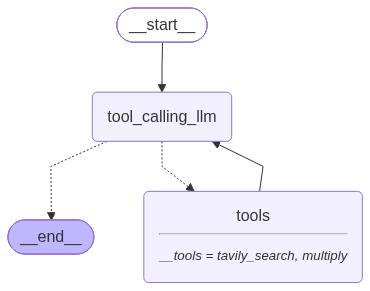

In [46]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image, display 

# Node Defination
def tool_calling_llm(state:State):
    return {"messages": llm_with_tool.invoke(state["messages"])}

# Graph
builder = StateGraph(State)
builder_graph = builder.add_node("tool_calling_llm",tool_calling_llm);
builder.add_node("tools", ToolNode(tools))


# Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)

builder.add_edge("tools", "tool_calling_llm")

graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [47]:
result = graph.invoke({"messages":"Give me the recent ai news and then multiple of 2 and 8"})
result

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiple of 2 and 8
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_f6d7e51b-c281-43d0-96f1-840260fc03fa)
 Call ID: fc_f6d7e51b-c281-43d0-96f1-840260fc03fa
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.riskinfo.ai/post/ai-insights-key-global-developments-in-november-2026", "title": "AI Insights: Key Global Developments in November 2026", "content": "In the defence sector, Shield AI announced plans to acquire radar developer Echodyne in a $5.3 billion deal, alongside a $2.5 billion funding round that valued the company at $28

In [48]:
result = graph.invoke({"messages":"Hi my name is Gyanesh"})
result

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hi my name is Gyanesh
================================== Ai Message ==================================

Hello Gyanesh! Nice to meet you. How can I help you today?


In [ ]:
result = graph.invoke({"messages":"What is my name"})
result

for m in result["messages"]:
    m.pretty_print()

#### ADDING MEMORY iN AGENTIC AI

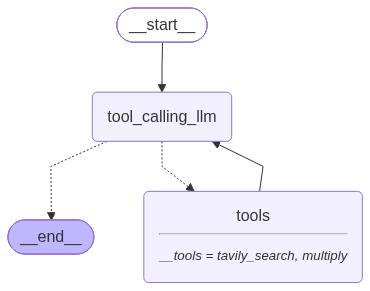

In [49]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image, display 
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

# Node Defination
def tool_calling_llm(state:State):
    return {"messages": llm_with_tool.invoke(state["messages"])}

# Graph
builder = StateGraph(State)
builder_graph = builder.add_node("tool_calling_llm",tool_calling_llm);
builder.add_node("tools", ToolNode(tools))


# Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)

builder.add_edge("tools", "tool_calling_llm")

graph = builder.compile(checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

In [52]:
config = {"configurable": {"thread_id":"1"}}

In [ ]:

response = graph.invoke({"messages":"Hi my name is Gyanesh"},config)


for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hi my name is Gyanesh
================================== Ai Message ==================================

Hello Gyanesh! Nice to meet you. How can I assist you today?


In [54]:
result = graph.invoke({"messages":"What is my name"}, config)
result

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hi my name is Gyanesh
================================== Ai Message ==================================

Hello Gyanesh! Nice to meet you. How can I assist you today?
================================ Human Message =================================

What is my name
================================== Ai Message ==================================

Your name is Gyanesh.


In [55]:
result = graph.invoke({"messages":"Do you remember me"}, config)
result

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hi my name is Gyanesh
================================== Ai Message ==================================

Hello Gyanesh! Nice to meet you. How can I assist you today?
================================ Human Message =================================

What is my name
================================== Ai Message ==================================

Your name is Gyanesh.
================================ Human Message =================================

Do you remember me
================================== Ai Message ==================================

I remember you from our earlier messages in this conversation— you introduced yourself as **Gyanesh**. Since I don’t retain information between separate sessions, that’s the extent of what I can recall right now. How can I help you further?


### STREAMING

Methods: .stream() and astream()

These methods are sync and async methods for streaming back results.
Additional parameters in streaming modes for graph state

values : This streams the full state of the graph after each node is called.
updates : This streams updates to the state of the graph after each node is called.

In [56]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

In [57]:
def superBot(state:State):
    return {"messages": [llm.invoke(state["messages"])]}

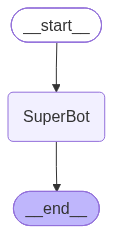

In [60]:
graph=StateGraph(State)

graph.add_node("SuperBot",superBot)

graph.add_edge(START, "SuperBot")
graph.add_edge("SuperBot", END)


graph_builder = graph.compile(checkpointer=memory)

display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [61]:
## Create a thread

config = {"configurable": {"thread_id":"3"}}

for chunk in graph_builder.stream({'messages': "Hi, y name is Krishd i like cricket"}, config, stream_mode="updates"):
    print(chunk)


{'SuperBot': {'messages': [AIMessage(content='Hey Krishd! 👋 Nice to meet you. Cricket’s a fantastic sport—do you have a favorite team or player? Whether you’re into Test matches, ODIs, or T20s, I’d love to hear what you enjoy most about the game!', additional_kwargs={'reasoning_content': 'The user says "Hi, y name is Krishd i like cricket". Likely they want a response. Probably greeting and ask about cricket or something. No disallowed content. Just respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 106, 'prompt_tokens': 82, 'total_tokens': 188, 'completion_time': 0.221555423, 'completion_tokens_details': {'reasoning_tokens': 42}, 'prompt_time': 0.013988314, 'prompt_tokens_details': None, 'queue_time': 0.162094304, 'total_time': 0.235543737}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c15aa9c1b7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20905-065b-71b6-a8e0-029e1b2ca3

In [62]:

for chunk in graph_builder.stream({'messages': "Hi, y name is Krish and i like cricket"}, config, stream_mode="values"):
    print(chunk)


{'messages': [HumanMessage(content='Hi, y name is Krishd i like cricket', additional_kwargs={}, response_metadata={}, id='661fefcf-a154-4c4d-8624-38b0e9c25f2d'), AIMessage(content='Hey Krishd! 👋 Nice to meet you. Cricket’s a fantastic sport—do you have a favorite team or player? Whether you’re into Test matches, ODIs, or T20s, I’d love to hear what you enjoy most about the game!', additional_kwargs={'reasoning_content': 'The user says "Hi, y name is Krishd i like cricket". Likely they want a response. Probably greeting and ask about cricket or something. No disallowed content. Just respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 106, 'prompt_tokens': 82, 'total_tokens': 188, 'completion_time': 0.221555423, 'completion_tokens_details': {'reasoning_tokens': 42}, 'prompt_time': 0.013988314, 'prompt_tokens_details': None, 'queue_time': 0.162094304, 'total_time': 0.235543737}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c15aa9c1b7', 'service_t

In [63]:
## Create a thread

config = {"configurable": {"thread_id":"4"}}

for chunk in graph_builder.stream({'messages': "Hi, y name is Krishd i like cricket"}, config, stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hi Krishd! Nice to meet you. 😊  \nCricket’s a great sport—do you have a favorite team or player? Are you more into watching matches, playing yourself, or maybe both? Let me know if there’s anything cricket‑related (or anything else) you’d like to chat about!', additional_kwargs={'reasoning_content': 'The user says "Hi, y name is Krishd i like cricket". Likely wants a response greeting. We should respond politely, ask about cricket preferences, maybe ask how can help. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 122, 'prompt_tokens': 82, 'total_tokens': 204, 'completion_time': 0.254679267, 'completion_tokens_details': {'reasoning_tokens': 49}, 'prompt_time': 0.004007219, 'prompt_tokens_details': None, 'queue_time': 0.584187755, 'total_time': 0.258686486}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_b1dd3e7a63', 'service_tier': 'on_demand', 'finish_reason': 'stop', '

In [64]:

for chunk in graph_builder.stream({'messages': "Hi, my name is Krish and i like cricket"}, config, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi, y name is Krishd i like cricket', additional_kwargs={}, response_metadata={}, id='aa73e512-626f-4374-90fe-01e27082c82a'), AIMessage(content='Hi Krishd! Nice to meet you. 😊  \nCricket’s a great sport—do you have a favorite team or player? Are you more into watching matches, playing yourself, or maybe both? Let me know if there’s anything cricket‑related (or anything else) you’d like to chat about!', additional_kwargs={'reasoning_content': 'The user says "Hi, y name is Krishd i like cricket". Likely wants a response greeting. We should respond politely, ask about cricket preferences, maybe ask how can help. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 122, 'prompt_tokens': 82, 'total_tokens': 204, 'completion_time': 0.254679267, 'completion_tokens_details': {'reasoning_tokens': 49}, 'prompt_time': 0.004007219, 'prompt_tokens_details': None, 'queue_time': 0.584187755, 'total_time': 0.25868648

### Human Feedback IN the Loop



In [90]:
llm = init_chat_model("groq:openai/gpt-oss-120b")

In [84]:
from typing import Annotated
from langchain_tavily import TavilySearch

from langchain_core.tools import tool
from typing_extensions import TypedDict
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.graph.message import add_messages

from langgraph.types import Command, interrupt

class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)

@tool
def human_assistance(query:str)->str:
    """Request assistance from a human."""
    human_response = interrupt({"query": query})
    return human_response["data"]

tool = TavilySearch(max_results=2)
tools= [tool, human_assistance]
llm_with_tool= llm.bind_tools(tools)


def chatbot(state: State):
    message = llm_with_tool.invoke(state["messages"])

    return {"messages": [message]}

graph_builder.add_node("chatbot", chatbot)

tool_node= ToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)



graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition
)

graph_builder.add_edge("tools","chatbot")

graph_builder.add_edge(START,"chatbot")
graph_builder


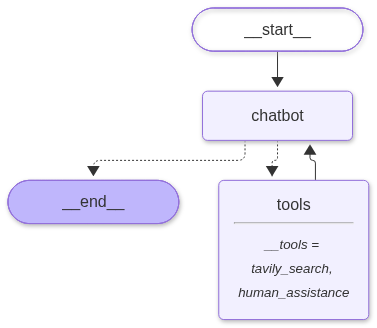

In [85]:
from langgraph.checkpoint.memory import MemorySaver
from IPython.display import Image, display 

memory = MemorySaver()
graph= graph_builder.compile(checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
user_input="I need some expert guidance and assitance for building an AI agent. Could you request assistance for me?."

config = {"configurable": {"thread_id":"1"}}

events = graph.stream(
    {"messages": user_input},
    config,
    stream_mode="values"
)

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I need some expert guide for building an AI agent. Could you request assistance for me?.
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_dbe28d6b-a5a4-4a78-ae3b-5960262c11f3)
 Call ID: fc_dbe28d6b-a5a4-4a78-ae3b-5960262c11f3
  Args:
    query: User requests expert guide for building an AI agent and asks to request assistance.
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_dbe28d6b-a5a4-4a78-ae3b-5960262c11f3)
 Call ID: fc_dbe28d6b-a5a4-4a78-ae3b-5960262c11f3
  Args:
    query: User requests expert guide for building an AI agent and asks to request assistance.


In [ ]:
user_input="I need some expert guidance and assitance for building an AI agent. Could you request assistance for me?."

config = {"configurable": {"thread_id":"2"}}

events = graph.stream(
    {"messages": user_input},
    config,
    stream_mode="values"
)

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I need some expert guidance and assitance for building an AI agent. Could you request assistance for me?.
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_c900e1ad-7b97-4aea-99f6-69ebec6ac5e0)
 Call ID: fc_c900e1ad-7b97-4aea-99f6-69ebec6ac5e0
  Args:
    query: User requests expert guidance and assistance for building an AI agent.
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_c900e1ad-7b97-4aea-99f6-69ebec6ac5e0)
 Call ID: fc_c900e1ad-7b97-4aea-99f6-69ebec6ac5e0
  Args:
    query: User requests expert guidance and assistance for building an AI agent.


In [95]:
human_response = (
    "We, the expert are here to help! We'd recommend you to check the LangGraph to build your agent. "
    "It is more reliable and extensible than simple autonomous agent"
)

human_command = Command(resume={"data": human_response})

# ✅ Pass human_command directly (not inside {"messages": ...})
events = graph.stream(
    human_command,
    config,
    stream_mode="values"
)

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()


================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_c900e1ad-7b97-4aea-99f6-69ebec6ac5e0)
 Call ID: fc_c900e1ad-7b97-4aea-99f6-69ebec6ac5e0
  Args:
    query: User requests expert guidance and assistance for building an AI agent.


NotImplementedError: Unsupported message type: <class 'langgraph.types.Command'>
For troubleshooting, visit: https://docs.langchain.com/oss/python/langchain/errors/MESSAGE_COERCION_FAILURE 